## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [2]:
import torch
print(torch.cuda.device_count())

1


In [3]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [4]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 1
GPU 0: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [5]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
# TRAIN_TOKENS = 300_000      # was 200_000_000
# VAL_TOKENS = 30_000         # was 5_000_000
TRAIN_BLOCK_SIZE = 1024
EPOCHS = 1
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 1024
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12
N_KV_HEAD = 4

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-grouped-query-lm"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

Configuration loaded.


In [6]:
!pip -q install ijson regex
import ijson, random, os
from huggingface_hub import hf_hub_download, HfApi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 4.7 MB/s eta 0:00:00


In [7]:
info = HfApi().dataset_info(HF_DATASET_REPO, files_metadata=True, token=HF_TOKEN)
for s in info.siblings:
    if "Phase_1_Pretraining" in s.rfilename:
        print(f"{s.rfilename:70s} {s.size/1e9:.2f} GB")

Phase_1_Pretraining/Test/test.json                                     0.00 GB
Phase_1_Pretraining/Train/train_acts.json                              0.73 GB
Phase_1_Pretraining/Train/train_high_courts.json                       10.67 GB
Phase_1_Pretraining/Train/train_supreme_court.json                     1.32 GB
Phase_1_Pretraining/Train/train_tribunals.json                         6.48 GB


In [8]:
from huggingface_hub import HfFileSystem

SOURCES = {
    "acts": "Phase_1_Pretraining/Train/train_acts.json",
    "high_courts": "Phase_1_Pretraining/Train/train_high_courts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "tribunals": "Phase_1_Pretraining/Train/train_tribunals.json",
}

print("ijson backend:", ijson.backend)

fs = HfFileSystem(token=HF_TOKEN)
QUOTA_BYTES, MAX_DOC_CHARS, KEEP_PROB = 8_000_000, 20_000, 0.3
random.seed(SEED)

with open("legal_sample.txt", "w", encoding="utf-8") as out:
    for name, fn in SOURCES.items():
        written = seen = 0
        with fs.open(f"datasets/{HF_DATASET_REPO}/{fn}", "rb") as f:
            for rec in ijson.items(f, "item"):
                seen += 1
                if random.random() > KEEP_PROB:
                    continue
                t = (rec.get("text") or "")[:MAX_DOC_CHARS]
                if not t:
                    continue
                out.write(t + "\n\n")
                written += len(t.encode("utf-8"))
                if written >= QUOTA_BYTES:
                    break
        print(f"{name}: {written/1e6:.1f} MB from the first {seen:,} docs")

ijson backend: yajl2_c
acts: 8.0 MB from the first 2,043 docs
high_courts: 8.0 MB from the first 10,448 docs
supreme_court: 8.0 MB from the first 1,613 docs
tribunals: 8.0 MB from the first 1,759 docs


In [9]:
tp = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TEST_FILE,
                     repo_type="dataset", token=HF_TOKEN)
test_data = json.load(open(tp, encoding="utf-8"))
print("examples:", len(test_data))
for k in list(test_data)[:3]:
    print(k, test_data[k]["text"][:300].replace("\n", " "), "\n")

test.json: 0.00B [00:00, ?B/s]

examples: 1000
1 The issue involved in these petitions is as to whether the acquisition proceedings can be challenged at a belated stage. The issue is no more res integra as the issue has been considered by this Court time and again. 6. When a person challenges Section 4 Notification on any ground, it should be chal 

2 Instead of taking cognizance of the offence, he has, in the exercise of his discretion, sent the complaint for investigation by police under Section 156." 12) In Tula Ram & Ors. vs. Kishore Singh (supra) again this Court considered order for investigation under [Section 2] 156 (3) on a complaint. Af 

3 (3) Any Magistrate empowered under section 190 may order such an investigation as above-mentioned. Section 173 - Report of police officer on completion of investigation (1) Every investigation under this Chapter shall be completed without unnecessary delay. (1A) The investigation in relation to rape 



## 4. Load Tokenizer

In [10]:
%%writefile a1_tokenizer.py
"""From-scratch byte-level BPE tokenizer (GPT-2 style), no external tokenizer libs.

Differences from the plain-bytes version:
  * Text is first split into "words" with a GPT-2 style regex, and merges never
    cross word boundaries. Training and encoding then work on *unique words*
    (with counts) instead of the whole corpus, which is orders of magnitude faster.
  * Training uses incremental pair counts + a lazy max-heap (no full rescan per merge).
  * Encoding applies merges per word by rank, with a word -> ids cache.
  * One special token, <|endoftext|>, used as EOS / PAD / BOS.

Interface:
    tok.encode(text, add_eos=False) -> list[int]
    tok.decode(ids, skip_special_tokens=True) -> str
    tok.vocab_size / tok.get_vocab_size()
    tok.eos_token_id, tok.pad_token_id, tok.bos_token_id
    tok.save(path) / ByteLevelBPE.load(path)
"""

from __future__ import annotations

import heapq
import json
import time
from collections import Counter, defaultdict

import regex as re  # `pip install regex` (needed for \p{L} / \p{N})

# GPT-2 pre-tokenization pattern
_PAT = re.compile(
    r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
)

EOS_TOKEN = "<|endoftext|>"


class ByteLevelBPE:
    def __init__(self):
        # ids 0-255 = raw bytes; 256.. = learned merges; last id = <|endoftext|>
        self.merges: dict[tuple[int, int], int] = {}      # (a, b) -> new_id (id order == rank order)
        self.itos: dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.eos_token_id = 256
        self.vocab_size = 257
        self._cache: dict[str, tuple] = {}

    # alias attributes so the tokenizer plugs into HF-style code
    @property
    def pad_token_id(self): return self.eos_token_id
    @property
    def bos_token_id(self): return self.eos_token_id

    def __len__(self): return self.vocab_size
    def get_vocab_size(self): return self.vocab_size

    def train(self, text: str, vocab_size: int, verbose: bool = False) -> None:
        """Learn (vocab_size - 257) merges; the final id is reserved for <|endoftext|>."""
        if vocab_size < 257:
            raise ValueError("vocab_size must be at least 257 (256 bytes + EOS)")
        num_merges = vocab_size - 257
        t0 = time.time()

        # 1) pre-tokenize and count unique words
        word_counts = Counter(_PAT.findall(text))
        words = [list(w.encode("utf-8")) for w in word_counts]
        freqs = list(word_counts.values())
        if verbose:
            print(f"[bpe] {len(words):,} unique words from {sum(freqs):,} total words")

        # 2) initial pair statistics
        stats: dict[tuple[int, int], int] = defaultdict(int)
        where: dict[tuple[int, int], set] = defaultdict(set)
        for wi, w in enumerate(words):
            f = freqs[wi]
            for p in zip(w, w[1:]):
                stats[p] += f
                where[p].add(wi)

        # lazy max-heap: (-count, a, b) -> highest count first, ties -> smallest (a, b)
        heap = [(-c, a, b) for (a, b), c in stats.items()]
        heapq.heapify(heap)

        self.merges, self.itos = {}, {i: bytes([i]) for i in range(256)}

        # 3) merge loop
        for i in range(num_merges):
            pair, count = None, 0
            while heap:
                negc, a, b = heapq.heappop(heap)
                if stats.get((a, b), 0) == -negc:   # skip stale heap entries
                    pair, count = (a, b), -negc
                    break
            if pair is None or count < 2:
                break

            new_id = 256 + i
            self.merges[pair] = new_id
            self.itos[new_id] = self.itos[pair[0]] + self.itos[pair[1]]

            touched = set()
            for wi in list(where[pair]):
                w, f = words[wi], freqs[wi]
                # remove this word's old pair contributions
                for p in zip(w, w[1:]):
                    stats[p] -= f
                    where[p].discard(wi)
                    touched.add(p)
                # apply merge (leftmost, non-overlapping)
                a, b = pair
                out, j, n = [], 0, len(w)
                while j < n:
                    if j < n - 1 and w[j] == a and w[j + 1] == b:
                        out.append(new_id); j += 2
                    else:
                        out.append(w[j]); j += 1
                words[wi] = out
                # add new pair contributions
                for p in zip(out, out[1:]):
                    stats[p] += f
                    where[p].add(wi)
                    touched.add(p)

            for p in touched:
                c = stats.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p[0], p[1]))
                else:
                    stats.pop(p, None)
                    where.pop(p, None)

            if verbose and (i % 1000 == 0 or i == num_merges - 1):
                print(f"[bpe] merge {i + 1}/{num_merges} | pair={pair} count={count:,} "
                      f"| elapsed={time.time() - t0:.1f}s")

        self.eos_token_id = 256 + len(self.merges)
        self.vocab_size = self.eos_token_id + 1
        self._cache = {}

    # Inference
    def _encode_word(self, word: str) -> tuple:
        hit = self._cache.get(word)
        if hit is not None:
            return hit
        ids = list(word.encode("utf-8"))
        merges = self.merges
        while len(ids) > 1:
            # pick the applicable merge learned earliest (lowest id)
            best, best_id = None, None
            for p in zip(ids, ids[1:]):
                nid = merges.get(p)
                if nid is not None and (best_id is None or nid < best_id):
                    best, best_id = p, nid
            if best is None:
                break
            a, b = best
            out, j, n = [], 0, len(ids)
            while j < n:
                if j < n - 1 and ids[j] == a and ids[j + 1] == b:
                    out.append(best_id); j += 2
                else:
                    out.append(ids[j]); j += 1
            ids = out
        res = tuple(ids)
        if len(self._cache) > 2_000_000:
            self._cache.clear()
        self._cache[word] = res
        return res

    def encode(self, text: str, add_eos: bool = False) -> list[int]:
        ids: list[int] = []
        for w in _PAT.findall(text):
            ids.extend(self._encode_word(w))
        if add_eos:
            ids.append(self.eos_token_id)
        return ids

    def decode(self, ids, skip_special_tokens: bool = True) -> str:
        if hasattr(ids, "tolist"):
            ids = ids.tolist()
        parts = []
        for i in ids:
            if i == self.eos_token_id:
                if not skip_special_tokens:
                    parts.append(EOS_TOKEN.encode("utf-8"))
                continue
            parts.append(self.itos[i])
        return b"".join(parts).decode("utf-8", errors="replace")

    def save(self, path: str) -> None:
        data = {
            "merges": [[a, b, nid] for (a, b), nid in self.merges.items()],
            "vocab_size": self.vocab_size,
            "eos_token_id": self.eos_token_id,
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f)

    @classmethod
    def load(cls, path: str) -> "ByteLevelBPE":
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls()
        for a, b, nid in data["merges"]:
            tok.merges[(a, b)] = nid
            tok.itos[nid] = tok.itos[a] + tok.itos[b]
        tok.eos_token_id = data["eos_token_id"]
        tok.vocab_size = data["vocab_size"]
        return tok


def train_tokenizer(train_text: str, vocab_size: int):
    """Train a byte-level BPE tokenizer on `train_text` and return it."""
    tok = ByteLevelBPE()
    tok.train(train_text, vocab_size, verbose=True)
    return tok

Writing a1_tokenizer.py


In [11]:
from a1_tokenizer import ByteLevelBPE

BPE_VOCAB_SIZE = 32_000
TOKENIZER_PATH = "bpe_tokenizer.json"
# BPE_VOCAB_SIZE = 2_000
# TOKENIZER_PATH = "bpe_tokenizer_test.json"

if os.path.exists(TOKENIZER_PATH):
    tokenizer = ByteLevelBPE.load(TOKENIZER_PATH)
else:
    with open("legal_sample.txt", encoding="utf-8") as f:
        corpus = f.read()
    tokenizer = ByteLevelBPE()
    tokenizer.train(corpus, BPE_VOCAB_SIZE, verbose=True)
    tokenizer.save(TOKENIZER_PATH)
print("Vocabulary size:", len(tokenizer))

[bpe] 74,916 unique words from 6,686,615 total words
[bpe] merge 1/1743 | pair=(32, 116) count=764,960 | elapsed=5.1s
[bpe] merge 1001/1743 | pair=(320, 114) count=2,496 | elapsed=7.8s
[bpe] merge 1743/1743 | pair=(764, 267) count=1,251 | elapsed=8.2s
Vocabulary size: 2000


In [12]:
# from transformers import AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
# tokenizer.pad_token = tokenizer.eos_token
# tokenizer.padding_side = "left"          # add this line
# print("Vocabulary size:", len(tokenizer))

## 5. Download Training Data From Hugging Face

In [13]:
from huggingface_hub import hf_hub_download

train_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Training file:")
print(train_file_path)

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


## 6. Create Train and Validation Tokens Set

In [14]:
import numpy as np

with open(train_file_path, "r", encoding="utf-8") as f:
    records = json.load(f)

train_arr = np.empty(TRAIN_TOKENS, dtype=np.uint16)
val_arr = np.empty(VAL_TOKENS, dtype=np.uint16)
n_train = n_val = 0

random.seed(SEED)
for data in records:
    tokens = tokenizer.encode(data["text"], add_eos=True)
    if random.random() < 0.05:
        take = min(len(tokens), VAL_TOKENS - n_val)
        val_arr[n_val:n_val + take] = tokens[:take]
        n_val += take
    else:
        take = min(len(tokens), TRAIN_TOKENS - n_train)
        train_arr[n_train:n_train + take] = tokens[:take]
        n_train += take
    if n_train >= TRAIN_TOKENS and n_val >= VAL_TOKENS:
        break

train_tokens = train_arr[:n_train]
val_tokens = val_arr[:n_val]
print(f"Train tokens: {n_train:,}")
print(f"Validation tokens: {n_val:,}")

Train tokens: 300,000
Validation tokens: 30,000


## 7. Create Token Blocks

In [15]:
def create_blocks(tokens, block_size):
    total_length = (len(tokens) // block_size) * block_size
    tokens = tokens[:total_length]
    return tokens.reshape(-1, block_size)

train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
val_blocks = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)

print("Training sequences:", len(train_blocks))
print("Validation sequences:", len(val_blocks))

Training sequences: 292
Validation sequences: 29


## 8. Create Datasets

In [16]:
from datasets import Dataset

train_dataset = Dataset.from_dict({"input_ids": train_blocks})
val_dataset = Dataset.from_dict({"input_ids": val_blocks})

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['input_ids'],
    num_rows: 292
})
Dataset({
    features: ['input_ids'],
    num_rows: 29
})


## 9. Define The Model

## Implementation for Grouped-Query Attention (GQA): 

In standard Multi-Head Attention (MHA), every query head has its own dedicated key and value head. In GQA, we divide the query heads into groups, and all queries within a single group share the same key and value heads. This drastically reduces the size of the KV-cache during inference (by a factor of the group size) while maintaining performance much closer to MHA than Multi-Query Attention (MQA) does.

In [17]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class GroupedQueryAttention(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        # Ensure dimensions cleanly divide
        assert n_embd % n_head == 0
        assert n_head % n_kv_head == 0
        
        self.n_head = n_head
        self.n_kv_head = n_kv_head
        self.head_dim = n_embd // n_head
        self.num_groups = n_head // n_kv_head  # Number of Q heads that share 1 KV head
        
        # Independent projections for Q, K, V to clearly handle differing head counts
        self.q_proj = nn.Linear(n_embd, n_embd)
        self.k_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.v_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        
        self.c_proj = nn.Linear(n_embd, n_embd)
        
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        
        self.register_buffer(
            "bias", 
            torch.tril(torch.ones(n_positions, n_positions)).view(1, 1, n_positions, n_positions)
        )

    def forward(self, x, layer_past=None):
        B, T, C = x.size()
        
        # 1. Project Q, K, V
        q = self.q_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        
        # 2. KV-Caching Logic
        if layer_past is not None:
            past_k, past_v = layer_past
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)
        
        present = (k, v)
        past_length = layer_past[0].size(-2) if layer_past is not None else 0
        seq_len = T + past_length
        
        # 3. GQA Broadcast: Repeat K and V to match the number of Q heads
        k = k.repeat_interleave(self.num_groups, dim=1)
        v = v.repeat_interleave(self.num_groups, dim=1)
        
        # 4. Attention Score Computation (Q @ K^T)
        att = q @ k.transpose(-2, -1)
        
        # 5. Score Scaling (1 / sqrt(d_k)) BEFORE Softmax
        att = att * (1.0 / math.sqrt(self.head_dim))
        
        # 6. Causal Masking
        mask = self.bias[:, :, past_length:past_length+T, :seq_len] == 0
        att = att.masked_fill(mask, float('-inf'))
        
        # 7. Softmax and Dropout
        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        
        # 8. Multiply by V and project
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        
        return self.resid_dropout(self.c_proj(y)), present


class GQATransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = GroupedQueryAttention(n_embd, n_head, n_kv_head, n_positions, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        
        self.mlp = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(approximate='tanh'),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x, layer_past=None):
        # RESIDUAL CONNECTION 1: Add attention output to the original input
        attn_out, present = self.attn(self.ln_1(x), layer_past=layer_past)
        x = x + attn_out
        
        # RESIDUAL CONNECTION 2: Add MLP output to the normalized attention output
        x = x + self.mlp(self.ln_2(x))
        
        return x, present


class ScratchGroupedQueryLM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, n_kv_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)

        self.h = nn.ModuleList([
            GQATransformerBlock(n_embd, n_head, n_kv_head, n_positions, dropout)
            for _ in range(n_layer)
        ])

        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, labels=None, past_key_values=None, attention_mask=None, **kwargs):
        B, T = input_ids.size()

        past_length = past_key_values[0][0].size(-2) if past_key_values is not None else 0
        pos = torch.arange(past_length, past_length + T, dtype=torch.long, device=input_ids.device)

        x = self.wte(input_ids) + self.wpe(pos)
        x = self.drop(x)

        presents = []
        for i, block in enumerate(self.h):
            layer_past = past_key_values[i] if past_key_values is not None else None
            x, present = block(x, layer_past=layer_past)
            presents.append(present)

        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if labels is not None:
            shift_logits = logits[..., :-1, :].contiguous()
            shift_labels = labels[..., 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))

        return {"loss": loss, "logits": logits, "past_key_values": tuple(presents)}
        

In [18]:
# from transformers import DataCollatorForLanguageModeling
# data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

def data_collator(features):
    ids = torch.tensor([f["input_ids"] for f in features], dtype=torch.long)
    return {"input_ids": ids, "attention_mask": torch.ones_like(ids), "labels": ids.clone()}

## 10. Training Arguments

In [19]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=3e-4,
    weight_decay=0.1,
    warmup_steps=500,
    # warmup_steps=5,
    lr_scheduler_type="cosine",
    fp16=torch.cuda.is_available(),
    eval_strategy="steps",
    eval_steps=1000,
    # eval_steps = 20,
    logging_steps=100,
    # logging_steps = 5,
    save_steps=1000,
    # save_steps = 20,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
    # logging_dir=os.path.join(OUTPUT_DIR, "logs")
)

In [20]:
import shutil
shutil.rmtree(MODEL_OUTPUT_DIR, ignore_errors=True)

## 11. Training

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ScratchGroupedQueryLM(
    vocab_size=tokenizer.vocab_size,
    n_positions=MODEL_CONTEXT_LENGTH,
    n_embd=N_EMBD,
    n_layer=N_LAYER,
    n_head=N_HEAD,
    n_kv_head=N_KV_HEAD
)

model = model.to(device)
model_size = sum(p.numel() for p in model.parameters())
print(f"ScratchGroupedQueryLM size: {model_size / 1e6:.2f}M parameters")

ScratchGroupedQueryLM size: 79.46M parameters


In [22]:
import torch
torch.cuda.empty_cache()
import gc
gc.collect()
print("GPU cache cleared.")

GPU cache cleared.


In [23]:
from transformers import Trainer
from transformers.trainer_utils import get_last_checkpoint

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    # processing_class=tokenizer
)

start_time = time.time()

last_checkpoint = None
if os.path.isdir(MODEL_OUTPUT_DIR):
    last_checkpoint = get_last_checkpoint(MODEL_OUTPUT_DIR)

trainer.train(resume_from_checkpoint=last_checkpoint)

training_time = (time.time() - start_time)

tokens_per_epoch = (len(train_dataset) * TRAIN_BLOCK_SIZE)

total_tokens = (tokens_per_epoch * EPOCHS)

tokens_per_second = (total_tokens / training_time)

print(f"Training time: {training_time / 3600:.2f} hours")
print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")

Step,Training Loss,Validation Loss
20,12.037360,5.979727


Training time: 0.01 hours
Training speed: 9,037 tokens/sec


## 12. Perplexity

In [24]:
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

Validation loss: 5.661435
Validation perplexity: 287.5609


## 13. Plot Training and Validation Loss

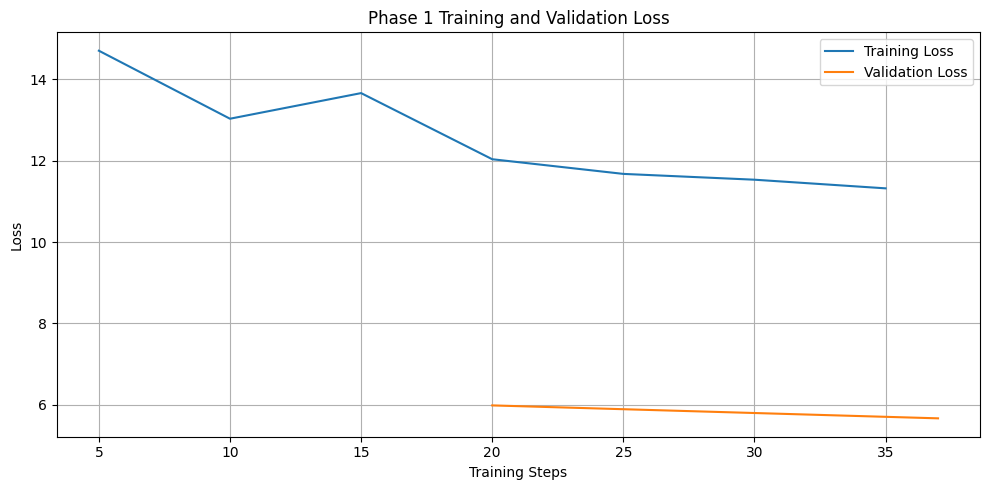

Loss plot saved to:
/kaggle/working/cs781_phase1/training_validation_loss.png


In [25]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

for log in logs:
    if ("loss" in log and "step" in log):
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if ("eval_loss" in log and "step" in log):
        eval_steps.append(log["step"])
        eval_loss.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [26]:
trainer.save_model(MODEL_OUTPUT_DIR)
# tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
tokenizer.save(os.path.join(MODEL_OUTPUT_DIR, "bpe_tokenizer.json"))

print("Final model saved to:")
print(MODEL_OUTPUT_DIR)

Final model saved to:
/kaggle/working/cs781_phase1/legal-grouped-query-lm


## 15. Push Model to Hugging Face Hub

In [27]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [28]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [29]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [30]:
# from transformers import AutoTokenizer, GPT2LMHeadModel
# import torch

# # generation_tokenizer = AutoTokenizer.from_pretrained(MODEL_OUTPUT_DIR)
# generation_tokenizer = ByteLevelBPE.load(os.path.join(MODEL_OUTPUT_DIR, "bpe_tokenizer.json"))
# # generation_tokenizer.padding_side = "left"          # add this line
# generation_model = GPT2LMHeadModel.from_pretrained(MODEL_OUTPUT_DIR)

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# generation_model = generation_model.to(device)
# generation_model.eval()
# generation_model.config.use_cache = True

# print("Device:", device)
# print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")

In [31]:
import os
import torch
from safetensors.torch import load_file

# 1. Load the tokenizer
generation_tokenizer = ByteLevelBPE.load(os.path.join(MODEL_OUTPUT_DIR, "bpe_tokenizer.json"))

# 2. Re-initialize your custom architecture with the EXACT same parameters used for training
generation_model = ScratchGroupedQueryLM(
    vocab_size=generation_tokenizer.vocab_size,
    n_positions=MODEL_CONTEXT_LENGTH,
    n_embd=N_EMBD, 
    n_layer=N_LAYER,
    n_head=N_HEAD,
    n_kv_head=N_KV_HEAD
)

# 3. Locate the saved weights (Trainer saves as either .bin or .safetensors)
safe_path = os.path.join(MODEL_OUTPUT_DIR, "model.safetensors")
bin_path = os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin")

if os.path.exists(bin_path):
    state_dict = torch.load(bin_path, map_location="cpu")
elif os.path.exists(safe_path):
    state_dict = load_file(safe_path)
else:
    raise FileNotFoundError("Could not find pytorch_model.bin or model.safetensors in output directory.")

# 4. Load weights into the model
generation_model.load_state_dict(state_dict)

# 5. Move to GPU and set to eval mode
generation_model = generation_model.to(device)
generation_model.eval()

print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")

Device: cuda
Parameters: 79.46M


## 19. Generate 128 Words
#### (words, not tokens)

In [32]:
# def generate_batch(prompts, model, tokenizer, device, target_words=128):
#     inputs = tokenizer(
#         prompts,
#         return_tensors="pt",
#         padding=True,
#         truncation=True,
#         max_length=MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
#     )

#     prompt_len = inputs["input_ids"].shape[1]     # fixed for the whole batch — use this, not per-example lengths
#     inputs = {key: value.to(device) for key, value in inputs.items()}

#     with torch.inference_mode():
#         outputs = model.generate(
#             **inputs,
#             max_new_tokens=MAX_GENERATION_TOKENS,
#             do_sample=True,
#             temperature=TEMPERATURE,
#             top_p=TOP_P,
#             pad_token_id=tokenizer.eos_token_id,
#         )

#     predictions = []
#     for i in range(len(prompts)):
#         generated_tokens = outputs[i, prompt_len:]          # changed: was input_lengths[i]
#         generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)
#         predictions.append(" ".join(generated_text.split()[:target_words]))

#     return predictions

In [33]:
import torch.nn.functional as F

def generate_batch(prompts, model, tokenizer, device, target_words=128):
    max_prompt = MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
    pad = tokenizer.eos_token_id
    
    encoded = [(tokenizer.encode(p)[-max_prompt:] or [pad]) for p in prompts]
    prompt_len = max(len(e) for e in encoded)
    
    input_ids = torch.full((len(encoded), prompt_len), pad, dtype=torch.long)
    for i, e in enumerate(encoded):
        input_ids[i, prompt_len - len(e):] = torch.tensor(e)
        
    input_ids = input_ids.to(device)
    
    model.eval()
    with torch.inference_mode():
        past_key_values = None
        current_input_ids = input_ids # Start with the full prompt
        
        for _ in range(MAX_GENERATION_TOKENS):
            # 1. Forward pass (returns cache)
            outputs = model(current_input_ids, past_key_values=past_key_values)
            
            # 2. Extract logits for the last token and update cache
            logits = outputs["logits"][:, -1, :] 
            past_key_values = outputs["past_key_values"]

            # For penalize already-generated tokens
            for b in range(logits.size(0)):
                seen = set(input_ids[b].tolist())
                seen.discard(tokenizer.eos_token_id)
                if not seen:
                    continue
                seen = torch.tensor(list(seen), device=device)
                logits[b, seen] = torch.where(
                    logits[b, seen] > 0,
                    logits[b, seen] / 1.2,
                    logits[b, seen] * 1.2
                )
            
            # 3. Apply Temperature
            logits = logits / (TEMPERATURE if TEMPERATURE > 0 else 1.0)
            
            # 4. Top-P (Nucleus) Filtering
            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_indices = torch.sort(probs, descending=True)
            cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
            
            sorted_indices_to_remove = cumulative_probs > TOP_P
            sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
            sorted_indices_to_remove[..., 0] = 0
            
            indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
            logits[indices_to_remove] = float('-inf')
            
            # 5. Sample the next token
            probs = F.softmax(logits, dim=-1)
            next_tokens = torch.multinomial(probs, num_samples=1)
            
            # 6. Append to full sequence (for decoding at the very end)
            input_ids = torch.cat((input_ids, next_tokens), dim=1)
            
            # 7. CRITICAL KV-CACHE STEP: Only pass the new token in the next loop iteration
            current_input_ids = next_tokens
            
    # Decode only the newly generated tokens
    predictions = []
    for i in range(len(prompts)):
        generated_tokens = input_ids[i, prompt_len:].tolist()
        text = tokenizer.decode(generated_tokens, skip_special_tokens=True)
        predictions.append(" ".join(text.split()[:target_words]))
        
    return predictions

## 20. Generate Predictions for the Test Set

In [34]:
predictions = {}
GENERATION_BATCH_SIZE = 32

items = list(test_data.items())
# items = list(test_data.items())[:32] 
total_examples = len(items)
print(f"Total test examples: {total_examples}")

for start in range(0, total_examples, GENERATION_BATCH_SIZE):
    batch = items[start:start + GENERATION_BATCH_SIZE]
    batch_ids = [str(example_id) for example_id, _ in batch]
    batch_prompts = [record["text"] for _, record in batch]

    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=generation_tokenizer,
        device=device,
        target_words=128
    )

    for example_id, prediction in zip(batch_ids, batch_predictions):
        predictions[example_id] = {"text": prediction}

    completed = start + len(batch)
    print(f"Completed {completed}/{total_examples} ({100 * completed / total_examples:.1f}%)")

Total test examples: 32
Completed 32/32 (100.0%)


## 21. Save prediction.json

In [35]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [36]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1/submission.zip
